# 10 EfficientNetB0 Transfer Learning for 40-Class Leaf Disease Classification (with SMOTE Support)

## Objective
Train an EfficientNetB0 compound-scaled convolutional architecture with SMOTE class balancing for multi-crop leaf classification:
- High parameter efficiency (5.3M parameters)
- Phase 1: Frozen base feature extraction
- Phase 2: Staged fine-tuning of top MBConv blocks
- Balanced data ingestion with SMOTE
- Performance evaluation and model export

**Prerequisites:** `01_data_check.ipynb`, `02_dataset_visualization.ipynb`, `03_targeted_augmentation.ipynb`, `04_data_preprocessing.ipynb`
**Next Step:** `08_model_evaluation.ipynb` or `11_prediction_testing.ipynb`

## 1. Import Required Libraries

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
import json
import os
import sys
from pathlib import Path

# Add utils to path
sys.path.insert(0, r'D:\cnn_model\utils')
import importlib
import transfer_learning_utils
importlib.reload(transfer_learning_utils)
from model_utils import evaluate_model
from transfer_learning_utils import (
    build_efficientnetb0_model,
    get_efficientnetb0_preprocessor,
    unfreeze_base_model,
    create_training_callbacks
)
from data_utils import create_image_label_mapping, get_dataset_summary, verify_dataset_structure

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Display TensorFlow version
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")



TensorFlow version: 2.15.0
GPU Available: []


## 2. Configuration and Data Loading

In [3]:
# Configuration dictionary for EfficientNetB0 training
CONFIG = {
    'num_classes': 40,
    'input_shape': (256, 256, 3),
    'batch_size': 8,
    'use_smote': True,
    'phase1_epochs': 25,
    'phase2_epochs': 20,
    'phase1_learning_rate': 3e-4,
    'phase2_learning_rate': 2e-5,
    'optimizer': 'adam',
    'dense_units': 256,
    'dropout_rate': 0.4,
    'num_unfreeze_layers': 40,
    'stage1_unfreeze_layers': 15,
    'stage1_epochs': 6,
    'stage2_epochs': 14,
    'reference_model_name': 'ResNet50',
    'reference_model_accuracy': 0.96,
    'data_dir': r'D:\cnn_model\Augmented_images',
    'smote_data_dir': r'D:\cnn_model\results\preprocessed_data_smote',
    'models_dir': r'D:\cnn_model\models\efficientnetb0',
    'logs_dir': r'D:\cnn_model\results\logs',
    'plots_dir': r'D:\cnn_model\results\plots',
    'confusion_matrix_dir': r'D:\cnn_model\results\confusion_matrix'
}

# Create directories if they don't exist
for dir_path in [CONFIG['models_dir'], CONFIG['logs_dir'], CONFIG['plots_dir'], CONFIG['confusion_matrix_dir']]:
    os.makedirs(dir_path, exist_ok=True)

# Validate and summarize the augmented-image dataset
if not os.path.exists(CONFIG['data_dir']):
    raise FileNotFoundError(f"Dataset directory not found: {CONFIG['data_dir']}")

print("Dataset summary:")
print(get_dataset_summary(CONFIG['data_dir']))

image_label_mapping, label_encoding = create_image_label_mapping(CONFIG['data_dir'])
num_classes = len(label_encoding)
class_names = sorted(label_encoding.keys(), key=lambda x: label_encoding[x])

# Create a dataframe for split management
image_records = pd.DataFrame(
    [(filepath, label) for filepath, label in image_label_mapping.items()],
    columns=['filepath', 'label']
)
image_records['label_idx'] = image_records['label'].map(label_encoding)

print(f"\n✓ Number of classes: {num_classes}")
print(f"  First 5 classes: {class_names[:5]}...")
print(f"  Total images found: {len(image_records)}")

# Stratified split: 80% train, 10% val, 10% test
train_df, temp_df = train_test_split(
    image_records,
    test_size=0.20,
    random_state=42,
    stratify=image_records['label_idx']
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['label_idx']
)

train_count = len(train_df)
val_count = len(val_df)
test_count = len(test_df)

print(f"\n✓ Dataset split:")
print(f"  - Train: {train_count} images")
print(f"  - Val: {val_count} images")
print(f"  - Test: {test_count} images")
print(f"  - Reference benchmark: {CONFIG['reference_model_name']} @ {CONFIG['reference_model_accuracy']*100:.2f}%")

# Data generators
train_datagen = ImageDataGenerator(
    preprocessing_function=get_efficientnetb0_preprocessor(),
    rotation_range=25,
    width_shift_range=0.10,
    height_shift_range=0.10,
    shear_range=0.08,
    zoom_range=0.15,
    brightness_range=(0.9, 1.1),
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)

plain_datagen = ImageDataGenerator(
    preprocessing_function=get_efficientnetb0_preprocessor()
)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepath',
    y_col='label',
    classes=class_names,
    target_size=CONFIG['input_shape'][:2],
    batch_size=CONFIG['batch_size'],
    class_mode='categorical',
    shuffle=True,
    seed=42
)

val_generator = plain_datagen.flow_from_dataframe(
    val_df,
    x_col='filepath',
    y_col='label',
    classes=class_names,
    target_size=CONFIG['input_shape'][:2],
    batch_size=CONFIG['batch_size'],
    class_mode='categorical',
    shuffle=False
)

test_generator = plain_datagen.flow_from_dataframe(
    test_df,
    x_col='filepath',
    y_col='label',
    classes=class_names,
    target_size=CONFIG['input_shape'][:2],
    batch_size=CONFIG['batch_size'],
    class_mode='categorical',
    shuffle=False
)

print(f"\n✓ Created TensorFlow image generators with batch_size={CONFIG['batch_size']}")
print(f"  - train_generator batches: {len(train_generator)}")
print(f"  - val_generator batches: {len(val_generator)}")
print(f"  - test_generator batches: {len(test_generator)}")

# Materialize validation/test arrays for evaluation and plots
def generator_to_arrays(generator):
    images_list = []
    labels_list = []
    for batch_index in range(len(generator)):
        batch_images, batch_labels = generator[batch_index]
        images_list.append(batch_images.astype('float32'))
        labels_list.append(batch_labels.astype('float32'))
    return np.concatenate(images_list, axis=0), np.concatenate(labels_list, axis=0)

X_val, y_val = generator_to_arrays(val_generator)
X_test, y_test = generator_to_arrays(test_generator)
y_train = keras.utils.to_categorical(np.asarray(train_generator.classes), num_classes=num_classes).astype('float32')

print(f"\n✓ Validation and test arrays loaded for evaluation")
print(f"  - X_val: {X_val.shape}, range: [{X_val.min():.4f}, {X_val.max():.4f}]")
print(f"  - X_test: {X_test.shape}, range: [{X_test.min():.4f}, {X_test.max():.4f}]")
print(f"  - y_train shape: {y_train.shape}")
print(f"  - y_val shape: {y_val.shape}")
print(f"  - y_test shape: {y_test.shape}")

# SMOTE is the balancing method; no class weights are computed or applied.
smote_split_path = os.path.join(CONFIG['smote_data_dir'], 'split_indices.json')
if CONFIG['use_smote'] and os.path.exists(smote_split_path):
    with open(smote_split_path, 'r') as f:
        smote_info = json.load(f)
    smote_train_count = smote_info.get('train_count', 0)
else:
    smote_train_count = 0

print(f"\n✓ SMOTE enabled: {CONFIG['use_smote']}")
print(f"  Existing SMOTE training images: {smote_train_count:,}")
print("  Class weights: not used")


Dataset summary:

DATASET SUMMARY
Total Images: 8600
Total Crops: 5

CROP-WISE BREAKDOWN:
------------------------------------------------------------

Brinjal:
  Healthy: 290
  Diseases: 9
    - Early_Leaf_spot: 315
    - Eggplant Wilt Disease: 295
    - Leaf_curl: 200
    - Little_leaf: 200
    - Magnessium: 200
    - Mosaic: 200
    - Nitrogen: 200
    - pest_damage: 265
    - Pottasium: 200

Castor:
  Healthy: 200
  Diseases: 6
    - Alternia Leaf Blight: 205
    - Bacterial Leaf Blight: 200
    - Cercospera Leaf Spot: 200
    - Peast_disease: 200
    - Pottassium: 200
    - Wilt: 200

Cumin:
  Healthy: 220
  Diseases: 4
    - Alternatia Blight: 200
    - insect_infection: 200
    - Powdery_Mildew: 200
    - Wilt: 200

Guava:
  Healthy: 255
  Diseases: 8
    - algal_leaf_spot: 200
    - anthrecnose: 200
    - Fungal infection: 200
    - Magnesium: 200
    - Nitrogen: 200
    - phosphorus: 200
    - pottasium: 200
    - Rust_fungal: 200

Papaya:
  Healthy: 200
  Diseases: 8
    - An

## 3. Build EfficientNetB0 Models with Custom Classification Heads

In [5]:
# Build initial EfficientNetB0 model (frozen base, high learning rate for feature extraction)
print("=" * 80)
print("PHASE 1: Building EfficientNetB0 Model (Frozen Base, High Learning Rate)")
print("=" * 80)

efficientnetb0_model = build_efficientnetb0_model(
    num_classes=CONFIG['num_classes'],
    input_shape=CONFIG['input_shape'],
    learning_rate=CONFIG['phase1_learning_rate'],
    dense_units=CONFIG['dense_units'],
    dropout_rate=CONFIG['dropout_rate'],
    label_smoothing=0.05
)

print("\nEfficientNetB0 Model Summary:")
efficientnetb0_model.summary()
print(f"\nTotal Parameters: {efficientnetb0_model.count_params():,}")
print(f"Trainable Parameters: {sum([tf.size(w).numpy() for w in efficientnetb0_model.trainable_weights]):,}")

PHASE 1: Building EfficientNetB0 Model (Frozen Base, High Learning Rate)

EfficientNetB0 Model Summary:
Model: "EfficientNetB0_Transfer_Learning"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 efficientnetb0 (Functional  (None, 8, 8, 1280)        4049571   
 )                                                               
                                                                 
 global_average_pooling2d_1  (None, 1280)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 head_batch_norm (BatchNorm  (None, 1280)              5120      
 alization)                                                      
                                                                 
 dense_head_1 (Dense)        (None, 256)               327936    
                                                              

## 4. Model Compilation Verification

In [6]:
# Verify model compilation
print("\nModel Compilation Details:")
print(f"Optimizer: {efficientnetb0_model.optimizer.__class__.__name__}")
print(f"Loss Function: {efficientnetb0_model.loss}")
print(f"Metrics: {efficientnetb0_model.metrics}")
print(f"\nPhase 1 Learning Rate: {CONFIG['phase1_learning_rate']}")
print(f"Phase 2 Learning Rate: {CONFIG['phase2_learning_rate']}")


Model Compilation Details:
Optimizer: Adam
Loss Function: <keras.src.losses.CategoricalCrossentropy object at 0x000002A486EC33A0>
Metrics: []

Phase 1 Learning Rate: 0.0003
Phase 2 Learning Rate: 2e-05


## 5. Data Preprocessing and Augmentation

In [4]:
# Verify the SMOTE-balanced data pipeline
print("Input Data Verification:")
print(f"SMOTE training images: {smote_train_count:,}")
print(f"Val generator samples: {val_generator.samples}")
print(f"Test generator samples: {test_generator.samples}")
print(f"Train batch shape: {train_generator[0][0].shape}")
print(f"Val batch shape: {val_generator[0][0].shape}")
print(f"Test batch shape: {test_generator[0][0].shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"y_test shape: {y_test.shape}")
print("SMOTE balancing: enabled")
print("Class weights: not used")

# Create a lightweight augmentation pipeline for visualization or standalone previews
train_augmentation = keras.Sequential([
    layers.RandomRotation(0.2, input_shape=CONFIG['input_shape']),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomFlip("horizontal"),
    layers.GaussianNoise(0.02)
], name='augmentation')

print(f"\nData Augmentation Pipeline: {len(train_augmentation.layers)} layers")
print("\nSMOTE-balanced training data is configured; no in-memory X_train array is required.")


Input Data Verification:
SMOTE training images: 10,240
Val generator samples: 860
Test generator samples: 860
Train batch shape: (8, 256, 256, 3)
Val batch shape: (8, 256, 256, 3)
Test batch shape: (8, 256, 256, 3)
y_train shape: (6880, 40)
y_val shape: (860, 40)
y_test shape: (860, 40)
SMOTE balancing: enabled
Class weights: not used


Data Augmentation Pipeline: 5 layers

SMOTE-balanced training data is configured; no in-memory X_train array is required.


## 6. Define Training Callbacks

In [7]:
# Create training callbacks for monitoring and early stopping
def create_callbacks(phase_name: str):
    """
    Create training callbacks for monitoring and early stopping.
    
    Args:
        phase_name: "phase1" or "phase2" to distinguish log files
    """
    callbacks = [
        # Early stopping to prevent overfitting
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),
        # Save best model based on validation accuracy
        keras.callbacks.ModelCheckpoint(
            filepath=f'{CONFIG["models_dir"]}/efficientnetb0_{phase_name}_best.h5',
            monitor='val_accuracy',
            save_best_only=True,
            verbose=0
        ),
        # Reduce learning rate on plateau
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),
        # Log to tensorboard
        keras.callbacks.TensorBoard(
            log_dir=f'{CONFIG["logs_dir"]}/efficientnetb0_{phase_name}',
            histogram_freq=1,
            write_graph=True
        )
    ]
    return callbacks

phase1_callbacks = create_callbacks('phase1')
print(f"Phase 1 Callbacks: {[cb.__class__.__name__ for cb in phase1_callbacks]}")

Phase 1 Callbacks: ['EarlyStopping', 'ModelCheckpoint', 'ReduceLROnPlateau', 'TensorBoard']


## 7. Phase 1 Training (Frozen Base, Feature Extraction)

In [ ]:
# Train EfficientNetB0 model - Phase 1 (frozen base)
print("=" * 80)
print("PHASE 1 TRAINING: EfficientNetB0 with Frozen Base")
print("=" * 80)
print(f"Epochs: {CONFIG['phase1_epochs']}")
print(f"Learning Rate: {CONFIG['phase1_learning_rate']}")
print(f"Batch Size: {CONFIG['batch_size']}")
print(f"Training Samples: {train_count}")
print("=" * 80)

efficientnetb0_history = efficientnetb0_model.fit(
    train_generator,
    epochs=CONFIG['phase1_epochs'],
    validation_data=val_generator,
    callbacks=phase1_callbacks,
    verbose=1
)

# Save training history
history_dict = {
    'loss': [float(x) for x in efficientnetb0_history.history['loss']],
    'accuracy': [float(x) for x in efficientnetb0_history.history['accuracy']],
    'val_loss': [float(x) for x in efficientnetb0_history.history['val_loss']],
    'val_accuracy': [float(x) for x in efficientnetb0_history.history['val_accuracy']]
}

with open(f'{CONFIG["logs_dir"]}/efficientnetb0_phase1_history.json', 'w') as f:
    json.dump(history_dict, f, indent=4)

print("\n" + "=" * 80)
print("PHASE 1 TRAINING COMPLETED")
print("=" * 80)
print(f"Final Train Loss: {efficientnetb0_history.history['loss'][-1]:.4f}")
print(f"Final Train Accuracy: {efficientnetb0_history.history['accuracy'][-1]:.4f}")
print(f"Final Val Loss: {efficientnetb0_history.history['val_loss'][-1]:.4f}")
print(f"Final Val Accuracy: {efficientnetb0_history.history['val_accuracy'][-1]:.4f}")


PHASE 1 TRAINING: EfficientNetB0 with Frozen Base
Epochs: 25
Learning Rate: 0.0003
Batch Size: 8
Training Samples: 6880
Epoch 1/25


860/860 [==============================] - ETA: 0s - loss: 2.7031 - accuracy: 0.3145

c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


860/860 [==============================] - 839s 965ms/step - loss: 2.7031 - accuracy: 0.3145 - val_loss: 1.3256 - val_accuracy: 0.6988 - lr: 3.0000e-04
Epoch 2/25
860/860 [==============================] - 679s 789ms/step - loss: 1.6729 - accuracy: 0.5920 - val_loss: 1.0442 - val_accuracy: 0.8023 - lr: 3.0000e-04
Epoch 3/25
860/860 [==============================] - 676s 785ms/step - loss: 1.4094 - accuracy: 0.6687 - val_loss: 0.9413 - val_accuracy: 0.8267 - lr: 3.0000e-04
Epoch 4/25
860/860 [==============================] - 697s 809ms/step - loss: 1.2586 - accuracy: 0.7279 - val_loss: 0.8693 - val_accuracy: 0.8756 - lr: 3.0000e-04
Epoch 5/25
860/860 [==============================] - 684s 795ms/step - loss: 1.1619 - accuracy: 0.7536 - val_loss: 0.8239 - val_accuracy: 0.8930 - lr: 3.0000e-04
Epoch 6/25
860/860 [==============================] - 719s 836ms/step - loss: 1.0929 - accuracy: 0.7866 - val_loss: 0.7929 - val_accuracy: 0.8988 - lr: 3.0000e-04
Epoch 7/25
860/860 [=============

## 8. Evaluate Phase 1 Model Performance

In [9]:
# Evaluate model on test set using model_utils
print("\n" + "=" * 80)
print("PHASE 1 EVALUATION ON TEST SET")
print("=" * 80)

metrics_phase1 = evaluate_model(
    efficientnetb0_model,
    X_test,
    y_test,
    class_names=class_names
)

report_phase1 = metrics_phase1['classification_report']
macro_avg_phase1 = report_phase1.get('macro avg', {})
weighted_avg_phase1 = report_phase1.get('weighted avg', {})

print("\nPhase 1 Test Set Metrics:")
print(f"  Accuracy: {metrics_phase1['accuracy']:.4f}")
print(f"  Macro Precision: {macro_avg_phase1.get('precision', 0.0):.4f}")
print(f"  Macro Recall: {macro_avg_phase1.get('recall', 0.0):.4f}")
print(f"  Macro F1-Score: {macro_avg_phase1.get('f1-score', 0.0):.4f}")
print(f"  Weighted Precision: {metrics_phase1['precision']:.4f}")
print(f"  Weighted Recall: {metrics_phase1['recall']:.4f}")
print(f"  Weighted F1-Score: {metrics_phase1['f1_score']:.4f}")

# Get confusion matrix for later visualization
cm_phase1 = np.array(metrics_phase1['confusion_matrix'])
print(f"\nConfusion Matrix shape: {cm_phase1.shape}")


PHASE 1 EVALUATION ON TEST SET

Phase 1 Test Set Metrics:
  Accuracy: 0.9477
  Macro Precision: 0.9507
  Macro Recall: 0.9487
  Macro F1-Score: 0.9477
  Weighted Precision: 0.9511
  Weighted Recall: 0.9477
  Weighted F1-Score: 0.9473

Confusion Matrix shape: (40, 40)


## 9. Generate Confusion Matrix and Class-wise Performance

In [10]:
# Save confusion matrix
# Save confusion matrix as numpy file
cm_phase1_path = f'{CONFIG["confusion_matrix_dir"]}/efficientnetb0_phase1_cm.npy'
np.save(cm_phase1_path, cm_phase1)
print(f"Confusion matrix saved: {cm_phase1_path}")

# Calculate class-wise metrics from confusion matrix
def calculate_class_metrics(cm, class_names):
    """Calculate precision, recall, F1 for each class."""
    metrics = {}
    for i in range(len(class_names)):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        
        metrics[class_names[i]] = {
            'precision': float(precision),
            'recall': float(recall),
            'f1_score': float(f1),
            'support': int(cm[i, :].sum())
        }
    return metrics

class_metrics_phase1 = calculate_class_metrics(cm_phase1, class_names)

# Save class metrics to JSON
with open(f'{CONFIG["logs_dir"]}/efficientnetb0_phase1_class_metrics.json', 'w') as f:
    json.dump(class_metrics_phase1, f, indent=4)

# Display top 5 best and worst classes by F1 score
f1_scores = {name: metrics['f1_score'] for name, metrics in class_metrics_phase1.items()}
sorted_f1 = sorted(f1_scores.items(), key=lambda x: x[1], reverse=True)

print("\nTop 5 Best Classes (by F1-Score):")
for class_name, f1 in sorted_f1[:5]:
    metrics = class_metrics_phase1[class_name]
    print(f"  {class_name:40s}: F1={f1:.4f}, Precision={metrics['precision']:.4f}, Recall={metrics['recall']:.4f}")

print("\nTop 5 Worst Classes (by F1-Score):")
for class_name, f1 in sorted_f1[-5:]:
    metrics = class_metrics_phase1[class_name]
    print(f"  {class_name:40s}: F1={f1:.4f}, Precision={metrics['precision']:.4f}, Recall={metrics['recall']:.4f}")

Confusion matrix saved: D:\cnn_model\results\confusion_matrix/efficientnetb0_phase1_cm.npy

Top 5 Best Classes (by F1-Score):
  Brinjal_Eggplant Wilt Disease           : F1=1.0000, Precision=1.0000, Recall=1.0000
  Brinjal_Leaf_curl                       : F1=1.0000, Precision=1.0000, Recall=1.0000
  Brinjal_Little_leaf                     : F1=1.0000, Precision=1.0000, Recall=1.0000
  Castor_Cercospera Leaf Spot             : F1=1.0000, Precision=1.0000, Recall=1.0000
  Castor_Pottassium                       : F1=1.0000, Precision=1.0000, Recall=1.0000

Top 5 Worst Classes (by F1-Score):
  Papaya_Mosaic                           : F1=0.8772, Precision=1.0000, Recall=0.7812
  Papaya_magnesiuam                       : F1=0.8718, Precision=0.8947, Recall=0.8500
  Brinjal_Pottasium                       : F1=0.8571, Precision=1.0000, Recall=0.7500
  Cumin_insect_infection                  : F1=0.8182, Precision=0.7500, Recall=0.9000
  Cumin_Alternatia Blight                 : F1=0.7568, 

## 10. Plot Training History and Evaluation Metrics

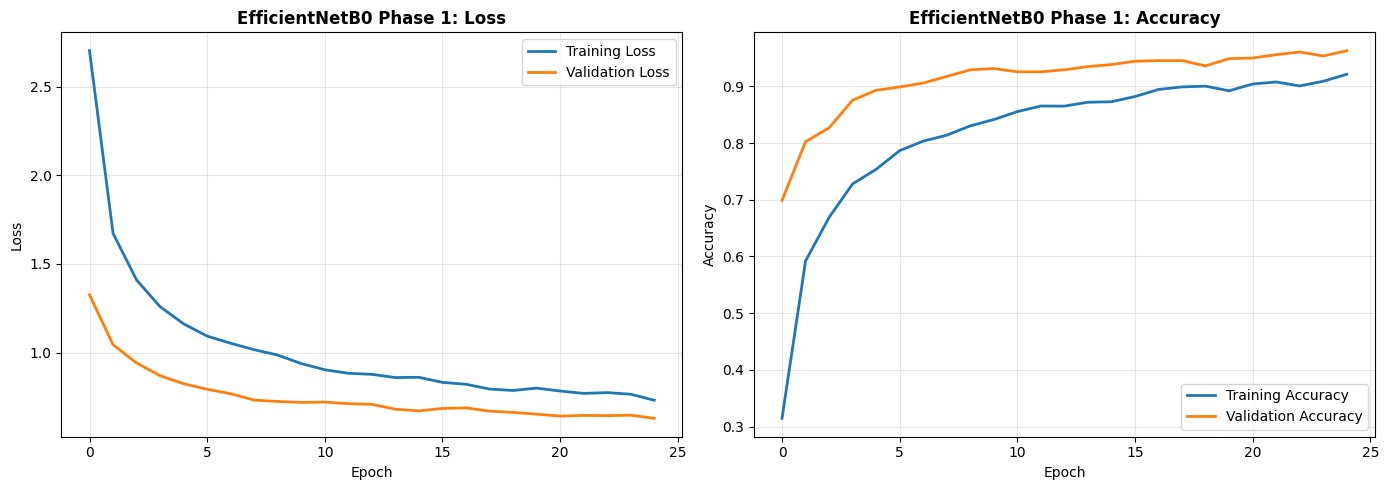

Training history plot saved


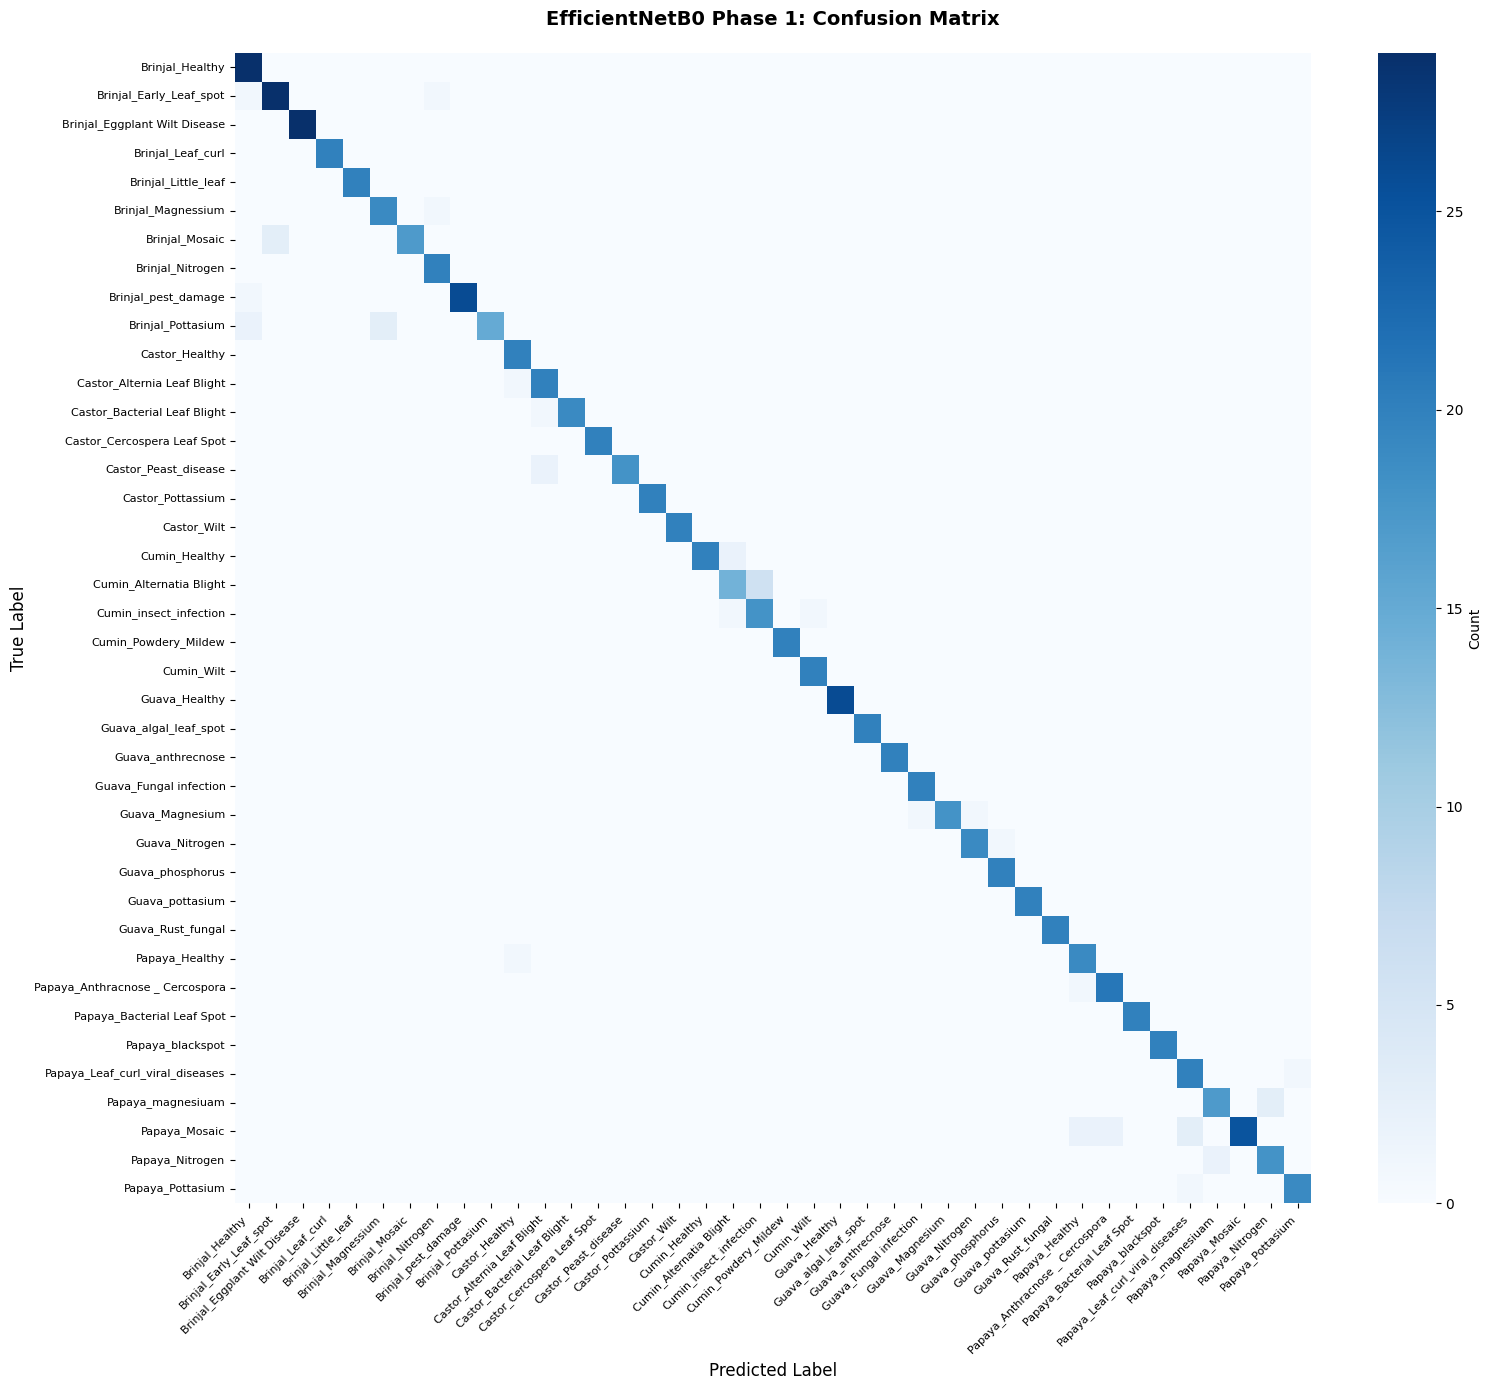

Confusion matrix plot saved


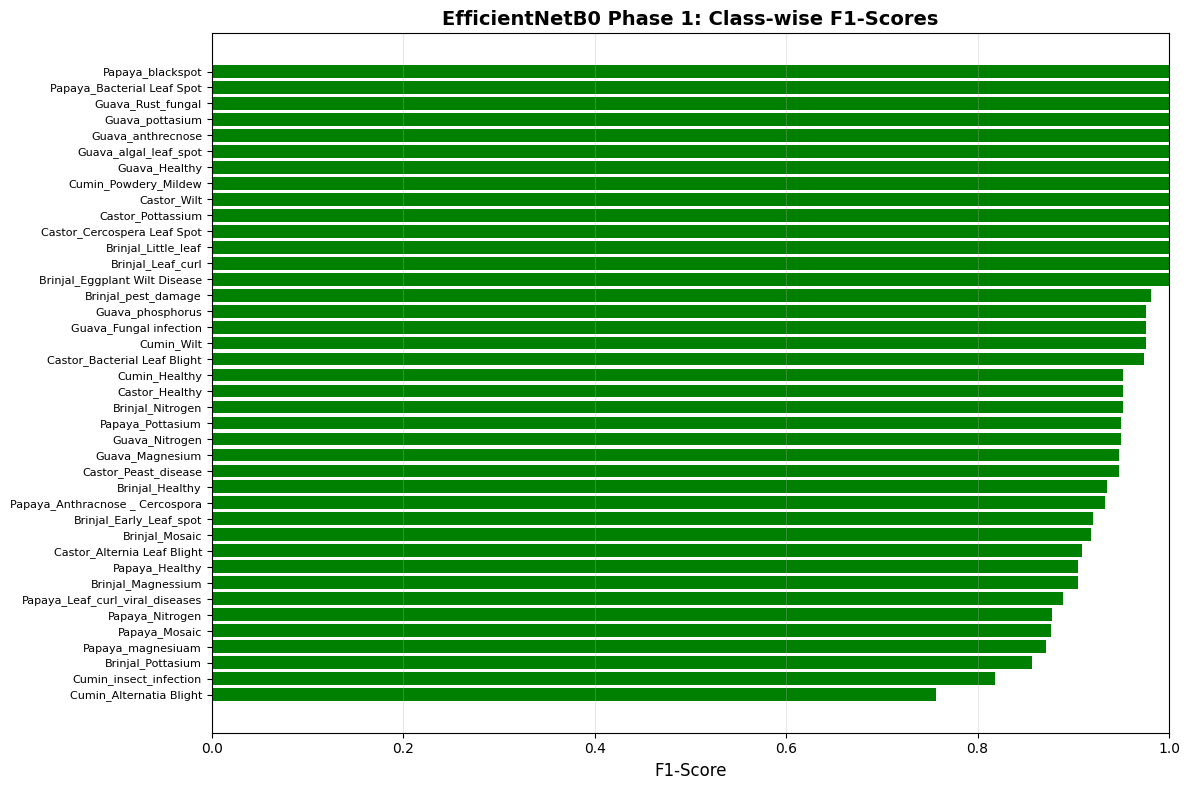

Class-wise F1 scores plot saved


In [11]:
# Plot training history - Loss and Accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(efficientnetb0_history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(efficientnetb0_history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('EfficientNetB0 Phase 1: Loss', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot Accuracy
axes[1].plot(efficientnetb0_history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[1].plot(efficientnetb0_history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[1].set_title('EfficientNetB0 Phase 1: Accuracy', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{CONFIG["plots_dir"]}/efficientnetb0_phase1_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("Training history plot saved")

# Plot Confusion Matrix for Phase 1
plt.figure(figsize=(16, 14))
sns.heatmap(cm_phase1, annot=False, fmt='d', cmap='Blues', cbar=True,
            xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Count'})
plt.title('EfficientNetB0 Phase 1: Confusion Matrix', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(f'{CONFIG["confusion_matrix_dir"]}/efficientnetb0_phase1_cm.png', dpi=300, bbox_inches='tight')
plt.show()

print("Confusion matrix plot saved")

# Plot class-wise F1 scores
f1_scores_sorted = dict(sorted(f1_scores.items(), key=lambda x: x[1]))
plt.figure(figsize=(12, 8))
colors = ['red' if f1 < 0.2 else 'orange' if f1 < 0.5 else 'green' for f1 in f1_scores_sorted.values()]
plt.barh(range(len(f1_scores_sorted)), list(f1_scores_sorted.values()), color=colors)
plt.yticks(range(len(f1_scores_sorted)), list(f1_scores_sorted.keys()), fontsize=8)
plt.xlabel('F1-Score', fontsize=12)
plt.title('EfficientNetB0 Phase 1: Class-wise F1-Scores', fontsize=14, fontweight='bold')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CONFIG["plots_dir"]}/efficientnetb0_phase1_f1_scores.png', dpi=300, bbox_inches='tight')
plt.show()

print("Class-wise F1 scores plot saved")

## 11. Fine-Tuning Strategy: Unfreeze and Train with Lower Learning Rate

In [14]:
# Fine-tuning strategy: staged unfreezing of EfficientNetB0 base model
print("\n" + "=" * 80)
print("PHASE 2: FINE-TUNING STRATEGY")
print("=" * 80)

# Locate the nested EfficientNetB0 base model inside the Sequential wrapper
base_model = next(
    layer for layer in efficientnetb0_model.layers
    if isinstance(layer, keras.Model) and layer.name.lower().startswith('efficientnetb0')
)

print(f"\nBase model layer count: {len(base_model.layers)}")
print(f"Stage 1: unfreeze last {CONFIG['stage1_unfreeze_layers']} layers for {CONFIG['stage1_epochs']} epochs")
print(f"Stage 2: unfreeze last {CONFIG['num_unfreeze_layers']} layers for {CONFIG['stage2_epochs']} epochs")
print(f"Phase 2 base learning rate: {CONFIG['phase2_learning_rate']}")
print("Batch normalization layers remain frozen during fine-tuning for stability")



PHASE 2: FINE-TUNING STRATEGY

Base model layer count: 238
Stage 1: unfreeze last 15 layers for 6 epochs
Stage 2: unfreeze last 40 layers for 14 epochs
Phase 2 base learning rate: 2e-05
Batch normalization layers remain frozen during fine-tuning for stability


## 12. Phase 2 Training (Fine-Tuning with Unfrozen Layers)

In [ ]:
# Train Phase 2 (staged fine-tuning with progressively unfrozen layers)
print("\n" + "=" * 80)
print("PHASE 2 TRAINING: EfficientNetB0 with Staged Fine-Tuning")
print("=" * 80)
phase1_checkpoint_path = os.path.join(CONFIG['models_dir'], 'efficientnetb0_phase1_best.h5')
if 'efficientnetb0_model' not in globals():
    if not os.path.exists(phase1_checkpoint_path):
        raise FileNotFoundError(f"Phase 1 checkpoint not found: {phase1_checkpoint_path}")
    print(f"Loading Phase 1 checkpoint: {phase1_checkpoint_path}")
    efficientnetb0_model = keras.models.load_model(phase1_checkpoint_path)
else:
    print("Using the existing in-memory Phase 1 model")
print(f"Stage 1 Epochs: {CONFIG['stage1_epochs']}")
print(f"Stage 1 Learning Rate: 5e-05")
print(f"Stage 2 Epochs: {CONFIG['stage2_epochs']}")
print(f"Stage 2 Learning Rate: {CONFIG['phase2_learning_rate']}")
print(f"Batch Size: {CONFIG['batch_size']}")
print("=" * 80)

# Stage 1: gently unfreeze the top layers to adapt the classifier and upper backbone
efficientnetb0_model = unfreeze_base_model(
    efficientnetb0_model,
    num_layers=CONFIG['stage1_unfreeze_layers'],
    learning_rate=5e-5
)
phase2_stage1_callbacks = create_training_callbacks(
    model_name='efficientnetb0_phase2_stage1',
    output_dir=CONFIG['models_dir'],
    patience_early_stop=8,
    patience_reduce_lr=3
)

print("\n-- Stage 1: warm-up fine-tuning --")
efficientnetb0_history_phase2_stage1 = efficientnetb0_model.fit(
    train_generator,
    epochs=CONFIG['stage1_epochs'],
    validation_data=val_generator,
    callbacks=phase2_stage1_callbacks,
    verbose=1
)

# Stage 2: widen the trainable window for deeper backbone adaptation
efficientnetb0_model = unfreeze_base_model(
    efficientnetb0_model,
    num_layers=CONFIG['num_unfreeze_layers'],
    learning_rate=CONFIG['phase2_learning_rate']
)
phase2_stage2_callbacks = create_training_callbacks(
    model_name='efficientnetb0_phase2_stage2',
    output_dir=CONFIG['models_dir'],
    patience_early_stop=10,
    patience_reduce_lr=5
)

print("\n-- Stage 2: broader backbone fine-tuning --")
efficientnetb0_history_phase2 = efficientnetb0_model.fit(
    train_generator,
    epochs=CONFIG['stage2_epochs'],
    validation_data=val_generator,
    callbacks=phase2_stage2_callbacks,
    verbose=1
)

# Save training histories
history_dict_phase2_stage1 = {
    'loss': [float(x) for x in efficientnetb0_history_phase2_stage1.history['loss']],
    'accuracy': [float(x) for x in efficientnetb0_history_phase2_stage1.history['accuracy']],
    'val_loss': [float(x) for x in efficientnetb0_history_phase2_stage1.history['val_loss']],
    'val_accuracy': [float(x) for x in efficientnetb0_history_phase2_stage1.history['val_accuracy']]
}

history_dict_phase2_stage2 = {
    'loss': [float(x) for x in efficientnetb0_history_phase2.history['loss']],
    'accuracy': [float(x) for x in efficientnetb0_history_phase2.history['accuracy']],
    'val_loss': [float(x) for x in efficientnetb0_history_phase2.history['val_loss']],
    'val_accuracy': [float(x) for x in efficientnetb0_history_phase2.history['val_accuracy']]
}

history_dict_phase2 = {
    'stage1': history_dict_phase2_stage1,
    'stage2': history_dict_phase2_stage2
}

with open(f'{CONFIG["logs_dir"]}/efficientnetb0_phase2_history.json', 'w') as f:
    json.dump(history_dict_phase2, f, indent=4)

print("\n" + "=" * 80)
print("PHASE 2 TRAINING COMPLETED")
print("=" * 80)
print(f"Stage 1 Final Train Loss: {efficientnetb0_history_phase2_stage1.history['loss'][-1]:.4f}")
print(f"Stage 1 Final Train Accuracy: {efficientnetb0_history_phase2_stage1.history['accuracy'][-1]:.4f}")
print(f"Stage 1 Final Val Loss: {efficientnetb0_history_phase2_stage1.history['val_loss'][-1]:.4f}")
print(f"Stage 1 Final Val Accuracy: {efficientnetb0_history_phase2_stage1.history['val_accuracy'][-1]:.4f}")
print(f"Stage 2 Final Train Loss: {efficientnetb0_history_phase2.history['loss'][-1]:.4f}")
print(f"Stage 2 Final Train Accuracy: {efficientnetb0_history_phase2.history['accuracy'][-1]:.4f}")
print(f"Stage 2 Final Val Loss: {efficientnetb0_history_phase2.history['val_loss'][-1]:.4f}")
print(f"Stage 2 Final Val Accuracy: {efficientnetb0_history_phase2.history['val_accuracy'][-1]:.4f}")



PHASE 2 TRAINING: EfficientNetB0 with Staged Fine-Tuning
Using the existing in-memory Phase 1 model
Stage 1 Epochs: 6
Stage 1 Learning Rate: 5e-05
Stage 2 Epochs: 14
Stage 2 Learning Rate: 2e-05
Batch Size: 8

-- Stage 1: warm-up fine-tuning --
Epoch 1/6


860/860 [==============================] - ETA: 0s - loss: 0.7039 - accuracy: 0.9305

c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


860/860 [==============================] - 738s 845ms/step - loss: 0.7039 - accuracy: 0.9305 - val_loss: 0.6412 - val_accuracy: 0.9605 - lr: 5.0000e-05
Epoch 2/6
860/860 [==============================] - 709s 824ms/step - loss: 0.6852 - accuracy: 0.9379 - val_loss: 0.6119 - val_accuracy: 0.9698 - lr: 5.0000e-05
Epoch 3/6
860/860 [==============================] - 746s 865ms/step - loss: 0.6685 - accuracy: 0.9408 - val_loss: 0.6027 - val_accuracy: 0.9733 - lr: 5.0000e-05
Epoch 4/6
860/860 [==============================] - 692s 804ms/step - loss: 0.6616 - accuracy: 0.9448 - val_loss: 0.6011 - val_accuracy: 0.9733 - lr: 5.0000e-05
Epoch 5/6
860/860 [==============================] - 737s 857ms/step - loss: 0.6526 - accuracy: 0.9464 - val_loss: 0.5980 - val_accuracy: 0.9698 - lr: 5.0000e-05
Epoch 6/6
860/860 [==============================] - 734s 853ms/step - loss: 0.6431 - accuracy: 0.9512 - val_loss: 0.5961 - val_accuracy: 0.9698 - lr: 5.0000e-05

-- Stage 2: broader backbone fine-tun

## 13. Evaluate Phase 2 Model and Compare with Phase 1


PHASE 2 EVALUATION ON TEST SET

Phase 2 Test Set Metrics:
  Accuracy: 0.9698
  Macro Precision: 0.9710
  Macro Recall: 0.9702
  Macro F1-Score: 0.9691
  Weighted F1-Score: 0.9697

PHASE 1 vs PHASE 2 COMPARISON
Metric                    Phase 1         Phase 2         Improvement    
----------------------------------------------------------------------
Accuracy                  0.9477          0.9698          +0.0221 (+2.3%)
Macro Precision           0.9507          0.9710          +0.0203 (+2.1%)
Macro Recall              0.9487          0.9702          +0.0215 (+2.3%)
Macro F1-Score            0.9477          0.9691          +0.0214 (+2.3%)
Weighted F1-Score         0.9473          0.9697          +0.0224 (+2.4%)

ResNet50 BENCHMARK COMPARISON
Reference model: ResNet50 (96.00%)
EfficientNetB0  : 96.98%
Difference      : +0.98%
✓ EfficientNetB0 matched or exceeded the ResNet50 benchmark


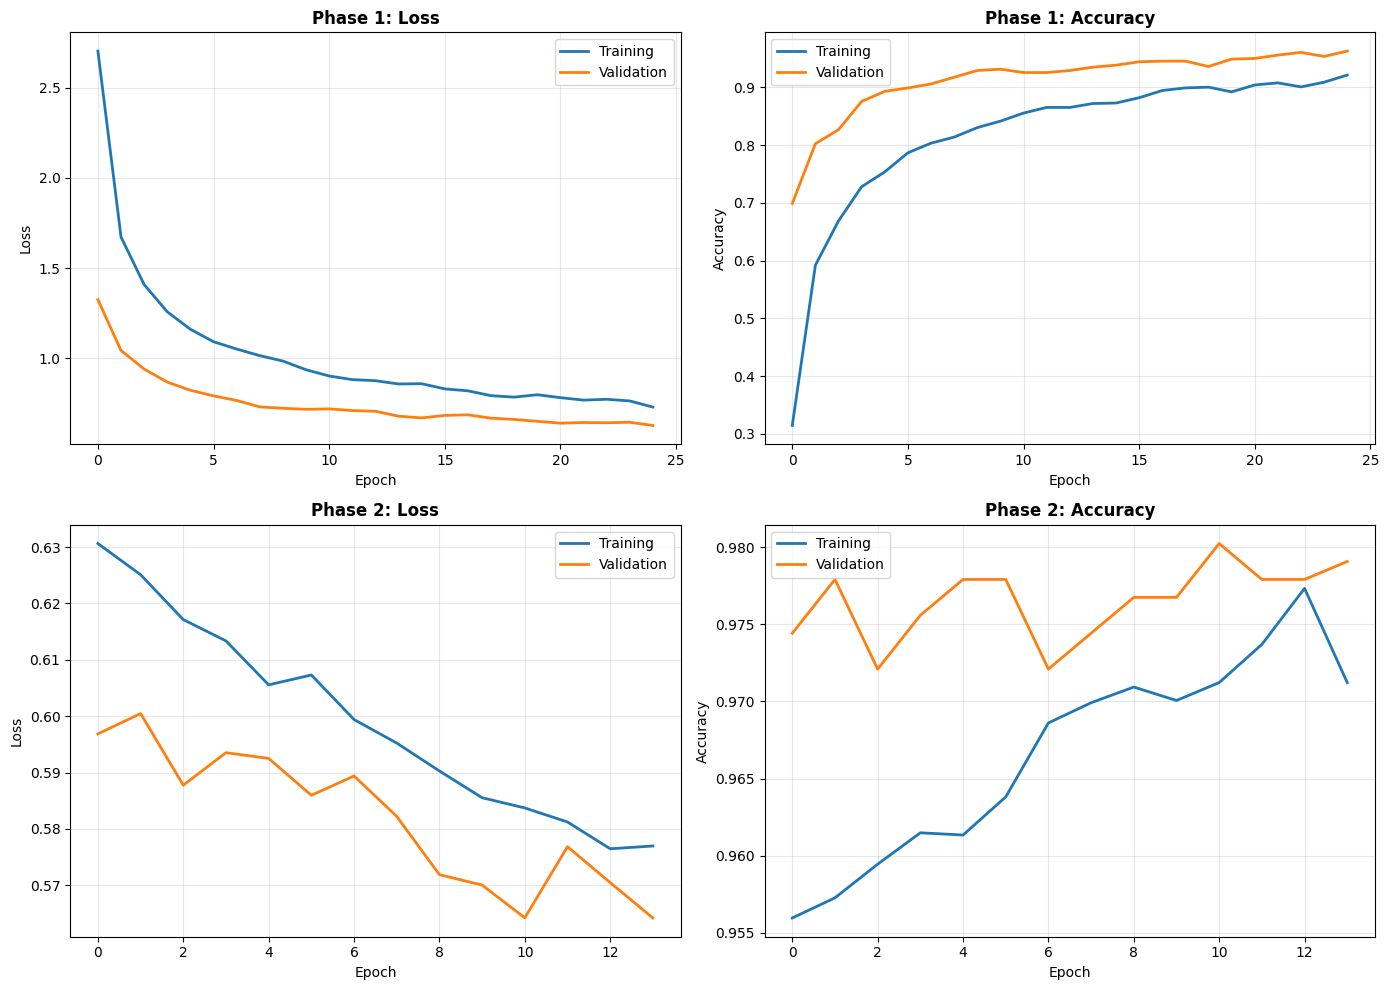


Phase 1 vs Phase 2 comparison plot saved
Phase 2 confusion matrix saved


In [15]:
# Evaluate Phase 2 model on test set
print("\n" + "=" * 80)
print("PHASE 2 EVALUATION ON TEST SET")
print("=" * 80)

if 'metrics_phase1' not in globals():
    if 'phase1_checkpoint_path' not in globals():
        phase1_checkpoint_path = os.path.join(CONFIG['models_dir'], 'efficientnetb0_phase1_best.h5')
    if not os.path.exists(phase1_checkpoint_path):
        raise FileNotFoundError(f"Phase 1 checkpoint not found: {phase1_checkpoint_path}")
    print(f"Loading Phase 1 baseline from: {phase1_checkpoint_path}")
    phase1_model = keras.models.load_model(phase1_checkpoint_path)
    metrics_phase1 = evaluate_model(
        phase1_model,
        X_test,
        y_test,
        class_names=class_names
    )
    report_phase1 = metrics_phase1['classification_report']
    macro_avg_phase1 = report_phase1.get('macro avg', {})
    weighted_avg_phase1 = report_phase1.get('weighted avg', {})

metrics_phase2 = evaluate_model(
    efficientnetb0_model,
    X_test,
    y_test,
    class_names=class_names
)

report_phase2 = metrics_phase2['classification_report']
macro_avg_phase2 = report_phase2.get('macro avg', {})
weighted_avg_phase2 = report_phase2.get('weighted avg', {})

phase1_summary = {
    'accuracy': metrics_phase1.get('accuracy', 0.0),
    'macro_precision': macro_avg_phase1.get('precision', 0.0),
    'macro_recall': macro_avg_phase1.get('recall', 0.0),
    'macro_f1': macro_avg_phase1.get('f1-score', 0.0),
    'weighted_f1': metrics_phase1.get('f1_score', 0.0)
}

phase2_summary = {
    'accuracy': metrics_phase2.get('accuracy', 0.0),
    'macro_precision': macro_avg_phase2.get('precision', 0.0),
    'macro_recall': macro_avg_phase2.get('recall', 0.0),
    'macro_f1': macro_avg_phase2.get('f1-score', 0.0),
    'weighted_f1': metrics_phase2.get('f1_score', 0.0)
}

print("\nPhase 2 Test Set Metrics:")
print(f"  Accuracy: {phase2_summary['accuracy']:.4f}")
print(f"  Macro Precision: {phase2_summary['macro_precision']:.4f}")
print(f"  Macro Recall: {phase2_summary['macro_recall']:.4f}")
print(f"  Macro F1-Score: {phase2_summary['macro_f1']:.4f}")
print(f"  Weighted F1-Score: {phase2_summary['weighted_f1']:.4f}")

cm_phase2 = np.array(metrics_phase2['confusion_matrix'])

# Compare Phase 1 vs Phase 2
print("\n" + "=" * 80)
print("PHASE 1 vs PHASE 2 COMPARISON")
print("=" * 80)
print(f"{'Metric':<25} {'Phase 1':<15} {'Phase 2':<15} {'Improvement':<15}")
print("-" * 70)

metrics_to_compare = [
    ('Accuracy', 'accuracy'),
    ('Macro Precision', 'macro_precision'),
    ('Macro Recall', 'macro_recall'),
    ('Macro F1-Score', 'macro_f1'),
    ('Weighted F1-Score', 'weighted_f1')
]

for metric_name, metric_key in metrics_to_compare:
    phase1_val = phase1_summary[metric_key]
    phase2_val = phase2_summary[metric_key]
    improvement = phase2_val - phase1_val
    improvement_pct = (improvement / phase1_val * 100) if phase1_val > 0 else 0
    print(f"{metric_name:<25} {phase1_val:<15.4f} {phase2_val:<15.4f} {improvement:+.4f} ({improvement_pct:+.1f}%)")

# Compare against ResNet50 benchmark
benchmark_accuracy = CONFIG['reference_model_accuracy']
efficientnet_accuracy = phase2_summary['accuracy']
accuracy_delta = efficientnet_accuracy - benchmark_accuracy
print("\n" + "=" * 80)
print(f"{CONFIG['reference_model_name']} BENCHMARK COMPARISON")
print("=" * 80)
print(f"Reference model: {CONFIG['reference_model_name']} ({benchmark_accuracy*100:.2f}%)")
print(f"EfficientNetB0  : {efficientnet_accuracy*100:.2f}%")
print(f"Difference      : {accuracy_delta*100:+.2f}%")

if accuracy_delta >= 0:
    print("✓ EfficientNetB0 matched or exceeded the ResNet50 benchmark")
else:
    print("⚠ EfficientNetB0 is below the ResNet50 benchmark; consider tuning phase1/phase2 settings")

# Plot comparison of training histories
from types import SimpleNamespace

phase1_history = globals().get('efficientnetb0_history')
if phase1_history is None:
    phase1_history_path = os.path.join(CONFIG['logs_dir'], 'efficientnetb0_phase1_history.json')
    if os.path.exists(phase1_history_path):
        with open(phase1_history_path, 'r') as f:
            phase1_history = SimpleNamespace(history=json.load(f))

phase2_history = globals().get('efficientnetb0_history_phase2')
if phase2_history is None:
    phase2_history_path = os.path.join(CONFIG['logs_dir'], 'efficientnetb0_phase2_history.json')
    if os.path.exists(phase2_history_path):
        with open(phase2_history_path, 'r') as f:
            phase2_history_json = json.load(f)
        phase2_history = SimpleNamespace(history=phase2_history_json.get('stage2', phase2_history_json))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot Phase 1 Loss
if phase1_history is not None:
    axes[0, 0].plot(phase1_history.history['loss'], label='Training', linewidth=2)
    axes[0, 0].plot(phase1_history.history['val_loss'], label='Validation', linewidth=2)
else:
    axes[0, 0].text(0.5, 0.5, 'Phase 1 history unavailable', ha='center', va='center')
axes[0, 0].set_title('Phase 1: Loss', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
if phase1_history is not None:
    axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot Phase 1 Accuracy
if phase1_history is not None:
    axes[0, 1].plot(phase1_history.history['accuracy'], label='Training', linewidth=2)
    axes[0, 1].plot(phase1_history.history['val_accuracy'], label='Validation', linewidth=2)
else:
    axes[0, 1].text(0.5, 0.5, 'Phase 1 history unavailable', ha='center', va='center')
axes[0, 1].set_title('Phase 1: Accuracy', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
if phase1_history is not None:
    axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot Phase 2 Loss
if phase2_history is not None:
    axes[1, 0].plot(phase2_history.history['loss'], label='Training', linewidth=2)
    axes[1, 0].plot(phase2_history.history['val_loss'], label='Validation', linewidth=2)
else:
    axes[1, 0].text(0.5, 0.5, 'Phase 2 history unavailable', ha='center', va='center')
axes[1, 0].set_title('Phase 2: Loss', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
if phase2_history is not None:
    axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot Phase 2 Accuracy
if phase2_history is not None:
    axes[1, 1].plot(phase2_history.history['accuracy'], label='Training', linewidth=2)
    axes[1, 1].plot(phase2_history.history['val_accuracy'], label='Validation', linewidth=2)
else:
    axes[1, 1].text(0.5, 0.5, 'Phase 2 history unavailable', ha='center', va='center')
axes[1, 1].set_title('Phase 2: Accuracy', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy')
if phase2_history is not None:
    axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{CONFIG["plots_dir"]}/efficientnetb0_phase1_vs_phase2_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nPhase 1 vs Phase 2 comparison plot saved")

# Save confusion matrix for Phase 2
np.save(f'{CONFIG["confusion_matrix_dir"]}/efficientnetb0_phase2_cm.npy', cm_phase2)
print(f"Phase 2 confusion matrix saved")

## 14. Save and Load Models

In [16]:
# Save final EfficientNetB0 model
print("\n" + "=" * 80)
print("SAVING MODELS")
print("=" * 80)

# Save as .h5 format (includes architecture and weights)
final_model_path = f'{CONFIG["models_dir"]}/efficientnetb0_final.h5'
efficientnetb0_model.save(final_model_path)
print(f"✓ Final model saved: {final_model_path}")

# Save as SavedModel format (recommended for production)
savedmodel_path = f'{CONFIG["models_dir"]}/efficientnetb0_final_savedmodel'
efficientnetb0_model.save(savedmodel_path, save_format='tf')
print(f"✓ SavedModel saved: {savedmodel_path}")

# Save model configuration and metadata
metadata = {
    'architecture': 'EfficientNetB0',
    'num_classes': CONFIG['num_classes'],
    'input_shape': CONFIG['input_shape'],
    'total_parameters': int(efficientnetb0_model.count_params()),
    'trainable_parameters': int(sum([tf.size(w).numpy() for w in efficientnetb0_model.trainable_weights])),
    'phase1_epochs': CONFIG['phase1_epochs'],
    'phase2_epochs': CONFIG['phase2_epochs'],
    'batch_size': CONFIG['batch_size'],
    'final_accuracy': float(metrics_phase2['accuracy']),
    'final_loss': float(efficientnetb0_history_phase2.history['val_loss'][-1]),
    'class_names': class_names
}

with open(f'{CONFIG["models_dir"]}/efficientnetb0_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"✓ Model metadata saved")

# Load and verify model
print("\n" + "=" * 80)
print("VERIFYING SAVED MODEL")
print("=" * 80)

loaded_model = keras.models.load_model(final_model_path)
print(f"✓ Model loaded successfully")
print(f"  Loaded model input shape: {loaded_model.input_shape}")
print(f"  Loaded model output shape: {loaded_model.output_shape}")

# Test prediction with loaded model
sample_predictions = loaded_model.predict(X_test[:5], verbose=0)
print(f"✓ Model predictions verified")
print(f"  Sample prediction shape: {sample_predictions.shape}")
print(f"  Sample prediction values (first image, top 5 classes):")
top_5_indices = np.argsort(sample_predictions[0])[::-1][:5]
for idx in top_5_indices:
    print(f"    {class_names[idx]}: {sample_predictions[0][idx]:.4f}")

print("\n" + "=" * 80)
print("EFFICIENTNETB0 TRANSFER LEARNING TRAINING COMPLETE")
print("=" * 80)
print(f"\nFinal Metrics:")
print(f"  Test Accuracy: {metrics_phase2['accuracy']:.4f}")
print(f"  Test F1-Score (Weighted): {phase2_summary['weighted_f1']:.4f}")
print(f"  Total training time: ~{CONFIG['phase1_epochs'] + CONFIG['phase2_epochs']} epochs")


SAVING MODELS


c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


✓ Final model saved: D:\cnn_model\models\efficientnetb0/efficientnetb0_final.h5
INFO:tensorflow:Assets written to: D:\cnn_model\models\efficientnetb0/efficientnetb0_final_savedmodel\assets


INFO:tensorflow:Assets written to: D:\cnn_model\models\efficientnetb0/efficientnetb0_final_savedmodel\assets


✓ SavedModel saved: D:\cnn_model\models\efficientnetb0/efficientnetb0_final_savedmodel
✓ Model metadata saved

VERIFYING SAVED MODEL
✓ Model loaded successfully
  Loaded model input shape: (None, 256, 256, 3)
  Loaded model output shape: (None, 40)
✓ Model predictions verified
  Sample prediction shape: (5, 40)
  Sample prediction values (first image, top 5 classes):
    Guava_Healthy: 0.9652
    Brinjal_Pottasium: 0.0238
    Brinjal_Healthy: 0.0023
    Guava_Rust_fungal: 0.0011
    Papaya_Leaf_curl_viral_diseases: 0.0009

EFFICIENTNETB0 TRANSFER LEARNING TRAINING COMPLETE

Final Metrics:
  Test Accuracy: 0.9698
  Test F1-Score (Weighted): 0.9697
  Total training time: ~45 epochs
